# Import and Setup

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The notebook runs inside notebooks/, so add the project root to Python's search path
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

from src.config import RAW_DIR

pd.set_option("display.float_format", "{:,.2f}".format)   # show 2 decimals
sns.set_theme(style="whitegrid")                          # clean chart style

# Load the raw data

In [6]:
nifty = pd.read_csv(RAW_DIR / "nifty50_daily.csv",
parse_dates = ["date"])
vix = pd.read_csv(RAW_DIR / "indiavix_daily.csv",
parse_dates = ["date"])

## Shape and 1st last rows

In [7]:
for name, df in [("NIFTY50", nifty), ("INDIAVIX", vix)]:
    print(f"{name}")
    print("Shape (rows, columns): ", df.shape)
    display(df.head())
    display(df.tail())

NIFTY50
Shape (rows, columns):  (2926, 7)


,date,open,high,low,close,volume,source
0,2015-01-02,"8,288.70","8,410.60","8,288.70","8,395.45",101900,yfinance
1,2015-01-05,"8,407.95","8,445.60","8,363.90","8,378.40",118200,yfinance
2,2015-01-06,"8,325.30","8,327.85","8,111.35","8,127.35",172800,yfinance
3,2015-01-07,"8,118.65","8,151.20","8,065.45","8,102.10",164100,yfinance
4,2015-01-08,"8,191.40","8,243.50","8,167.30","8,234.60",143800,yfinance


,date,open,high,low,close,volume,source
2921,2026-11-16,"25,206.15","25,337.60","25,172.10","25,291.10",352900,yfinance
2922,2026-11-17,"25,277.30","25,501.35","25,267.30","25,387.40",342500,yfinance
2923,2026-11-18,"25,323.15","25,390.80","25,141.80","25,227.95",300000,yfinance
2924,2026-11-19,"25,186.80","25,514.30","25,104.80","25,514.30",328800,yfinance
2925,2026-11-20,"25,368.00","25,808.80","25,345.20","25,800.60",428300,yfinance


INDIAVIX
Shape (rows, columns):  (2915, 7)


,date,open,high,low,close,volume,source
0,2015-01-01,15.12,15.51,14.76,15.03,0,yfinance
1,2015-01-02,15.03,15.03,13.48,13.80,0,yfinance
2,2015-01-05,13.80,14.41,13.15,14.15,0,yfinance
3,2015-01-06,14.15,17.87,13.46,17.42,0,yfinance
4,2015-01-07,17.42,19.07,16.50,18.14,0,yfinance


,date,open,high,low,close,volume,source
2910,2026-11-16,15.50,15.94,13.60,15.68,0,yfinance
2911,2026-11-17,15.68,15.68,14.04,15.52,0,yfinance
2912,2026-11-18,15.52,16.03,14.59,15.57,0,yfinance
2913,2026-11-19,15.57,16.90,15.52,16.11,0,yfinance
2914,2026-11-20,16.11,17.56,15.03,17.32,0,yfinance


### Structure and Data Types

In [8]:
nifty.info()
print()
vix.info()

<class 'pandas.DataFrame'>
RangeIndex: 2926 entries, 0 to 2925
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    2926 non-null   datetime64[us]
 1   open    2926 non-null   float64       
 2   high    2926 non-null   float64       
 3   low     2926 non-null   float64       
 4   close   2926 non-null   float64       
 5   volume  2926 non-null   int64         
 6   source  2926 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 183.0 KB

<class 'pandas.DataFrame'>
RangeIndex: 2915 entries, 0 to 2914
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    2915 non-null   datetime64[us]
 1   open    2915 non-null   float64       
 2   high    2915 non-null   float64       
 3   low     2915 non-null   float64       
 4   close   2915 non-null   float64       
 5   volume  2915 non-null

In [9]:
display(nifty.describe())
display(vix.describe())

,date,open,high,low,close,volume
count,2926,"2,926.00","2,926.00","2,926.00","2,926.00","2,926.00"
mean,2020-12-15 05:01:40.888585,"15,249.06","15,318.69","15,158.59","15,240.67","326,384.38"
min,2015-01-02 00:00:00,"7,023.65","7,034.20","6,825.80","6,970.60",0.00
25%,2017-12-23 00:00:00,"10,063.30","10,112.75","10,004.79","10,058.44","205,825.00"
50%,2020-12-17 12:00:00,"13,617.27","13,655.90","13,461.02","13,584.47","275,100.00"
75%,2023-12-03 06:00:00,"20,499.99","20,599.88","20,426.74","20,582.08","392,675.00"
max,2026-11-20 00:00:00,"26,333.70","26,373.20","26,210.05","26,328.55","1,811,000.00"
std,NaN,"6,060.85","6,084.71","6,037.56","6,062.54","184,652.48"


,date,open,high,low,close,volume
count,2915,"2,915.00","2,915.00","2,915.00","2,915.00","2,915.00"
mean,2020-12-09 00:08:53.516295,16.53,17.24,15.16,16.53,0.00
min,2015-01-01 00:00:00,9.15,9.40,8.18,9.15,0.00
25%,2017-12-13 12:00:00,13.15,13.65,11.90,13.15,0.00
50%,2020-12-03 00:00:00,15.29,15.92,13.98,15.29,0.00
75%,2023-11-29 12:00:00,18.26,19.05,16.79,18.26,0.00
max,2026-11-20 00:00:00,83.61,86.64,75.97,83.61,0.00
std,NaN,6.02,6.37,5.62,6.02,0.00


### numerical vs categorical features

In [12]:
numeric_cols = nifty.select_dtypes(include="number").columns.tolist()
other_cols = nifty.select_dtypes(exclude="number").columns.tolist()

print("Numerical features :", numeric_cols)
print("Non-numerical      :", other_cols)

Numerical features : ['open', 'high', 'low', 'close', 'volume']
Non-numerical      : ['date', 'source']


### Missing Values and Unique Counts

In [13]:
for name in [("NIFTY50", nifty), ("INDIAVIX", vix)]:
    print(f"{name}")
    print("Missing values per columns", df.isna().sum())
    print("\nUnique values per column: ", df.nunique())
    print()

('NIFTY50',            date      open      high       low     close  volume    source
0    2015-01-02  8,288.70  8,410.60  8,288.70  8,395.45  101900  yfinance
1    2015-01-05  8,407.95  8,445.60  8,363.90  8,378.40  118200  yfinance
2    2015-01-06  8,325.30  8,327.85  8,111.35  8,127.35  172800  yfinance
3    2015-01-07  8,118.65  8,151.20  8,065.45  8,102.10  164100  yfinance
4    2015-01-08  8,191.40  8,243.50  8,167.30  8,234.60  143800  yfinance
...         ...       ...       ...       ...       ...     ...       ...
2921 2026-11-16 25,206.15 25,337.60 25,172.10 25,291.10  352900  yfinance
2922 2026-11-17 25,277.30 25,501.35 25,267.30 25,387.40  342500  yfinance
2923 2026-11-18 25,323.15 25,390.80 25,141.80 25,227.95  300000  yfinance
2924 2026-11-19 25,186.80 25,514.30 25,104.80 25,514.30  328800  yfinance
2925 2026-11-20 25,368.00 25,808.80 25,345.20 25,800.60  428300  yfinance

[2926 rows x 7 columns])
Missing values per columns date      0
open      0
high      0
low       0

### Date Converage (rows per year)

In [14]:
coverage = pd.DataFrame({
    "NIFTY50": nifty.groupby(nifty["date"].dt.year).size(),
    "INDIAVIX": vix.groupby(vix["date"].dt.year).size(),
})
display(coverage)

,NIFTY50,INDIAVIX
date,,
2015,244,246
2016,244,246
2017,248,248
2018,245,246
2019,241,242
2020,250,249
2021,248,238
2022,248,247
2023,245,245


In [15]:
print(nifty.nunique())
print(vix.nunique())

date      2926
open      2912
high      2907
low       2910
close     2902
volume    2136
source       1
dtype: int64
date      2915
open      1263
high      1307
low       1191
close     1266
volume       1
source       1
dtype: int64


### check the VIX open quirk

In [16]:
import numpy as np

vix_open_eq = np.isclose(vix["open"], vix["close"].shift(1)).mean()
nifty_open_eq = np.isclose(nifty["open"], nifty["close"].shift(1)).mean()

print(f"VIX open equals previous close on {vix_open_eq:.1%} of days")
print(f"Nifty open equals previous close on {nifty_open_eq:.1%} of days")

VIX open equals previous close on 98.8% of days
Nifty open equals previous close on 0.1% of days


### Statistics Table

In [18]:
def summary_stats(series, mode_decimals):
    """Core descritive statistics for one price series."""
    return pd.Series({
        "count": series.count(),
        "mean": series.mean(),
        "median": series.median(),
        "mode (rounded)": series.round(mode_decimals).mode().iloc[0],
        "std": series.std(),
        "min": series.min(),
        "max": series.max(),
        "skewness": series.skew(),
        "kurtosis": series.kurt(),
    })

stats = pd.DataFrame({
    "NIFTY50 close": summary_stats(nifty["close"], mode_decimals=-2),
    "INDIAVIX close": summary_stats(vix["close"], mode_decimals=0),
})

display(stats)

,NIFTY50 close,INDIAVIX close
count,"2,926.00","2,915.00"
mean,"15,240.67",16.53
median,"13,584.47",15.29
mode (rounded),"10,800.00",14.00
std,"6,062.54",6.02
min,"6,970.60",9.15
max,"26,328.55",83.61
skewness,0.40,4.31
kurtosis,-1.31,31.08


### Year by Year Nifty Summary

In [19]:
yearly = nifty.groupby(nifty["date"].dt.year)["close"].agg(["first", "last", "min", "max"])
yearly["return_%"] = yearly["last"].pct_change() * 100 # year-end to year-end

display(yearly)

,first,last,min,max,return_%
date,,,,,
2015,"8,395.45","7,946.35","7,558.80","8,996.25",NaN
2016,"7,791.30","8,185.80","6,970.60","8,952.50",3.01
2017,"8,179.50","10,530.70","8,179.50","10,531.50",28.65
2018,"10,442.20","10,862.55","9,998.05","11,738.50",3.15
2019,"10,792.50","12,168.45","10,604.35","12,271.80",12.02
2020,"12,182.50","13,981.75","7,610.25","13,981.95",14.90
2021,"14,018.50","17,354.05","13,634.60","18,477.05",24.12
2022,"17,625.70","18,105.30","15,293.50","18,812.50",4.33
2023,"18,197.45","21,731.40","16,945.05","21,778.70",20.03


## Helper to save charts

In [20]:
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Tidy the layout, save the chart as a PNG for the report, then show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()

### Nifty price with moving averages

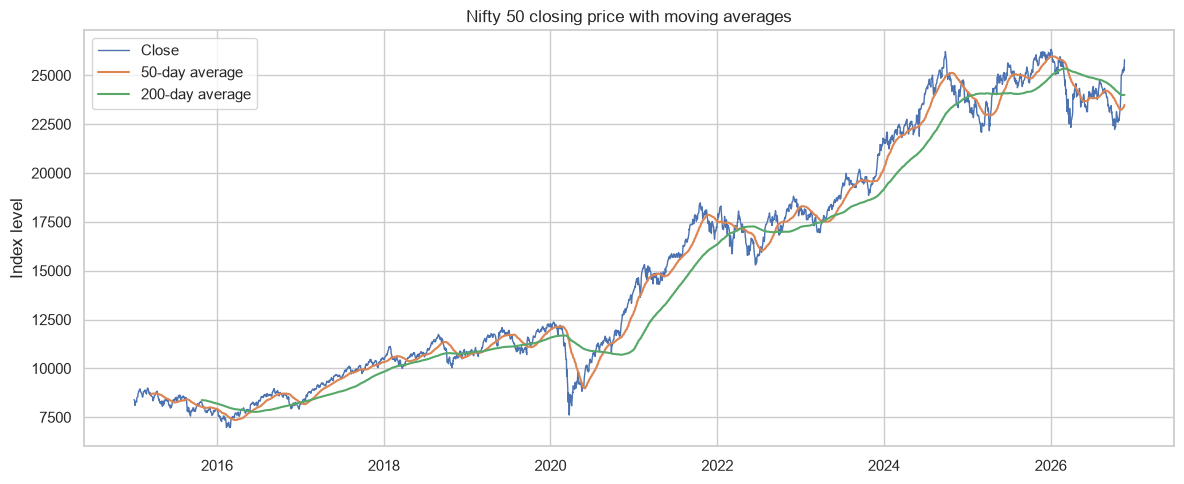

In [22]:
close = nifty.set_index("date")["close"]     # a series indexed by date
ma50 = close.rolling(50).mean()              # average of the last 50 days
ma200 = close.rolling(200).mean()            # average of the last 200 days

plt.figure(figsize=(12, 5))
plt.plot(close, label="Close", linewidth=1)
plt.plot(ma50, label="50-day average")
plt.plot(ma200, label="200-day average")
plt.title("Nifty 50 closing price with moving averages")
plt.ylabel("Index level")
plt.legend()
save_fig("01_nifty_price_ma")

### India VIX overtime

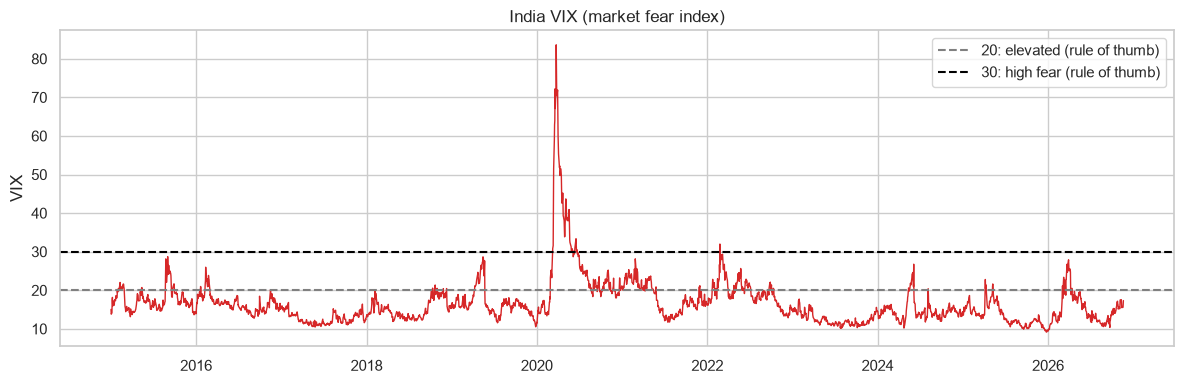

In [23]:
vix_close = vix.set_index("date")["close"]

plt.figure(figsize=(12, 4))
plt.plot(vix_close, linewidth=1, color="tab:red")
plt.axhline(20, linestyle="--", color="gray", label="20: elevated (rule of thumb)")
plt.axhline(30, linestyle="--", color="black", label="30: high fear (rule of thumb)")
plt.title("India VIX (market fear index)")
plt.ylabel("VIX")
plt.legend()
save_fig("02_india_vix")

## Nifty and VIX stacked

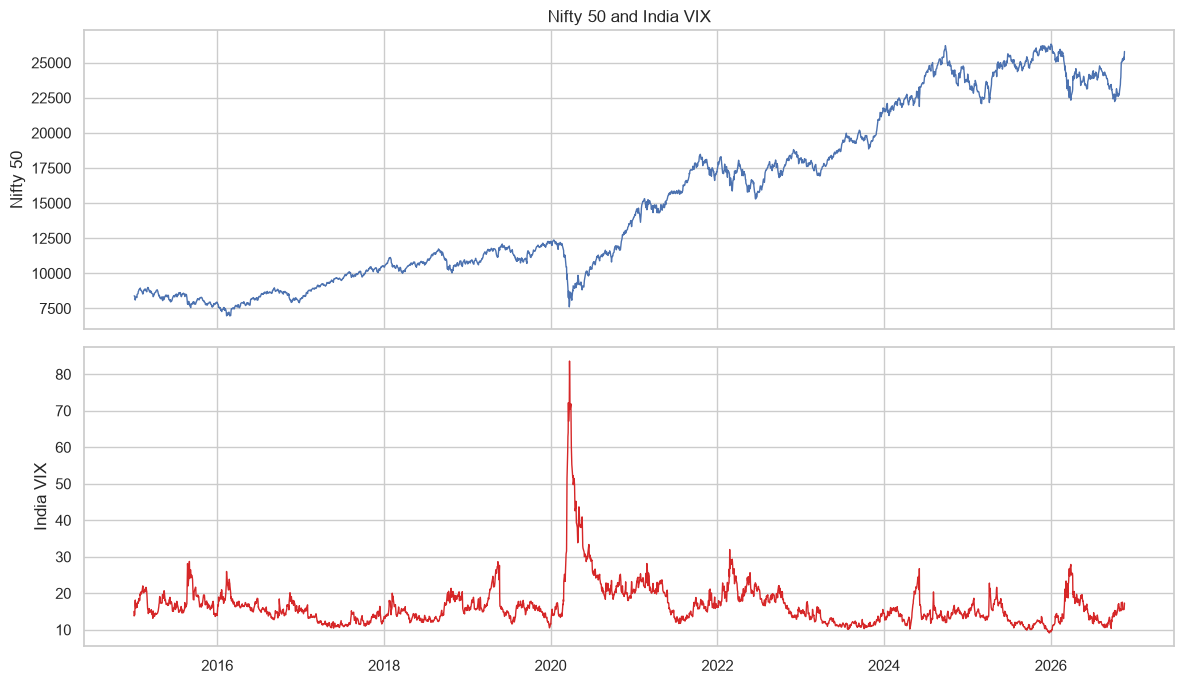

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax1.plot(close, linewidth=1)
ax1.set_ylabel("Nifty 50")
ax1.set_title("Nifty 50 and India VIX")

ax2.plot(vix_close, linewidth=1, color="tab:red")
ax2.set_ylabel("India VIX")

save_fig("03_nifty_vs_vix")

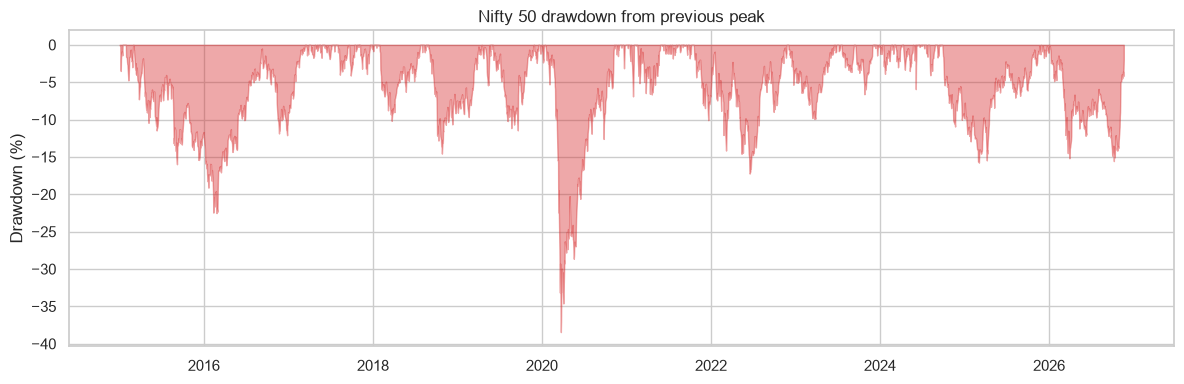

Worst drawdown: -38.4% on 2020-03-23


In [25]:
drawdown = close / close.cummax() - 1     # distance below the highest close so far

plt.figure(figsize=(12, 4))
plt.fill_between(drawdown.index, drawdown * 100, 0, color="tab:red", alpha=0.4)
plt.title("Nifty 50 drawdown from previous peak")
plt.ylabel("Drawdown (%)")
save_fig("04_nifty_drawdown")

print(f"Worst drawdown: {drawdown.min():.1%} on {drawdown.idxmin().date()}")

### Compute Returns

In [26]:
rets = nifty[["date", "close"]].set_index("date").copy()

rets["ret"] = rets["close"].pct_change() # simple daily return
rets["log_ret"] = np.log(rets["close"] / rets["close"].shift(1)) # Log return
rets = rets.dropna()  # First day has no previous close

display(rets.head())
print("Max difference between simple and log return: ")
((rets["ret"] - rets["log_ret"]).abs().max())

,close,ret,log_ret
date,,,
2015-01-05,"8,378.40",-0.00,-0.00
2015-01-06,"8,127.35",-0.03,-0.03
2015-01-07,"8,102.10",-0.00,-0.00
2015-01-08,"8,234.60",0.02,0.02
2015-01-09,"8,284.50",0.01,0.01


Max difference between simple and log return: 


np.float64(0.009232903905799617)

### Key Statistics of retruns

In [27]:
r = rets["ret"]

print(f"Mean daily return        : {r.mean():.3%}")
print(f"Daily std (volatility)   : {r.std():.3%}")
print(f"Annualised volatility    : {r.std() * np.sqrt(252):.1%}")
print(f"Skewness                 : {r.skew():.2f}")
print(f"Excess kurtosis          : {r.kurt():.2f}")
print(f"Share of up days         : {(r > 0).mean():.1%}")
print(f"Best day                 : {r.max():.2%} on {r.idxmax().date()}")
print(f"Worst day                : {r.min():.2%} on {r.idxmin().date()}")

Mean daily return        : 0.044%
Daily std (volatility)   : 1.018%
Annualised volatility    : 16.2%
Skewness                 : -0.99
Excess kurtosis          : 16.87
Share of up days         : 53.4%
Best day                 : 8.76% on 2020-04-07
Worst day                : -12.98% on 2020-03-23


## Histogram Versus a Normal Curve

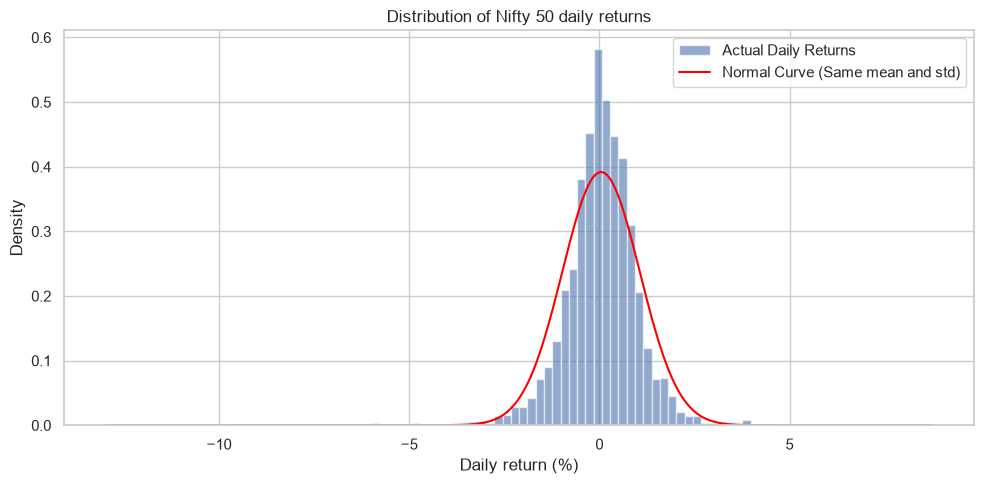

In [29]:
from scipy import stats

plt.figure(figsize=(10, 5))
plt.hist(r * 100, bins=100, density=True, alpha=0.6, label="Actual Daily Returns")

x = np.linspace(r.min() * 100, r.max() * 100, 400)
plt.plot(x, stats.norm.pdf(x, r.mean() * 100, r.std() * 100),
         color="red", label="Normal Curve (Same mean and std)")

plt.title("Distribution of Nifty 50 daily returns")
plt.xlabel("Daily return (%)")
plt.ylabel("Density")
plt.legend()
save_fig("05_return_distribution")

### Returns over time (Valatility Clustering)

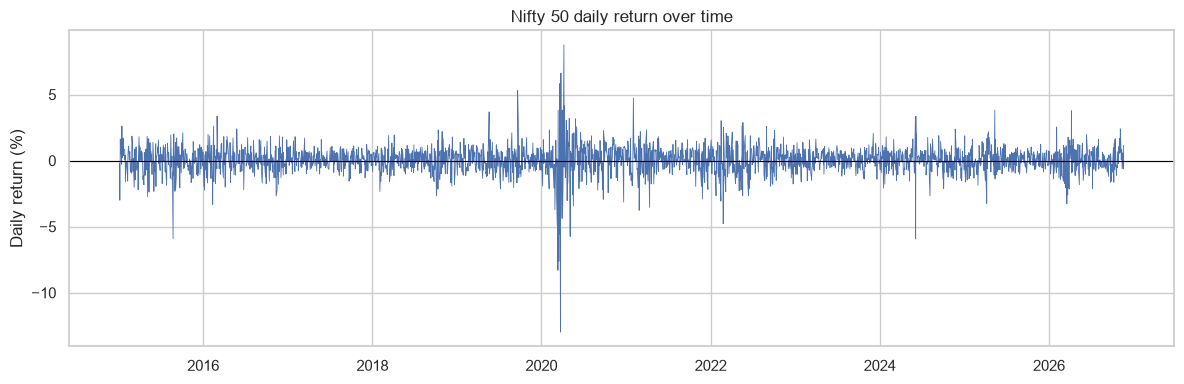

In [30]:
plt.figure(figsize=(12, 4))
plt.plot(r * 100, linewidth= 0.6)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Nifty 50 daily return over time")
plt.ylabel("Daily return (%)")
save_fig("06_daily_returns_over_time")

### Returns by year 

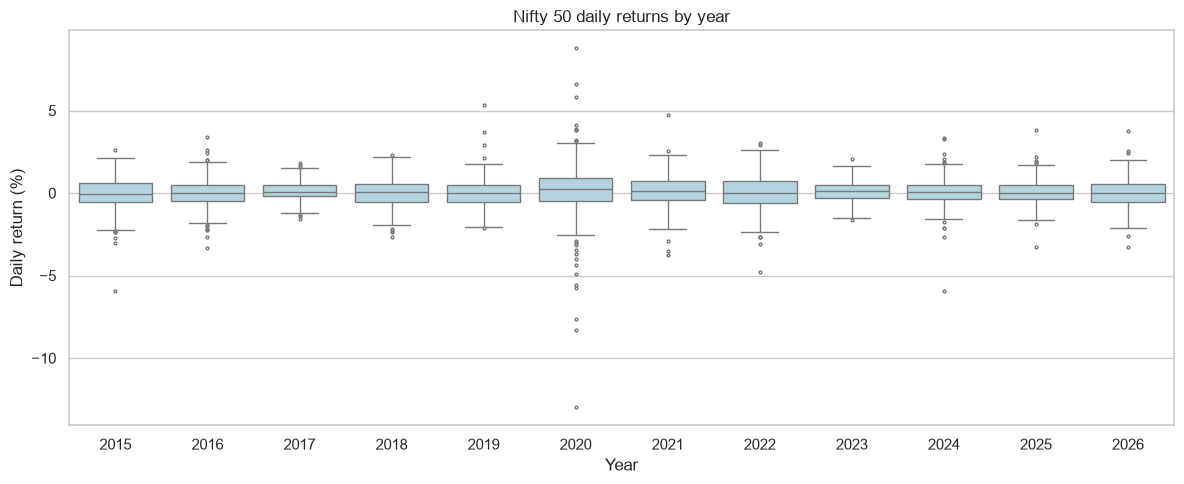

In [31]:
plt.figure(figsize=(12, 5))
sns.boxplot(x=rets.index.year, y=r * 100, color="lightblue", fliersize=2)
plt.title("Nifty 50 daily returns by year")
plt.xlabel("Year")
plt.ylabel("Daily return (%)")
save_fig("07_returns_boxplot_by_year")

### Best and Worst Day

In [32]:
print("5 worst days:")
display((r.nsmallest(5) * 100).round(2).to_frame("return_%"))

print("5 best days:")
display((r.nlargest(5) * 100).round(2).to_frame("return_%"))

5 worst days:


,return_%
date,
2020-03-23,-12.98
2020-03-12,-8.30
2020-03-16,-7.61
2024-06-04,-5.93
2015-08-24,-5.92


5 best days:


,return_%
date,
2020-04-07,8.76
2020-03-25,6.62
2020-03-20,5.83
2019-09-20,5.32
2021-02-01,4.74


### Join Nifty and VIX, and Built analysis columns

In [33]:
vix_close = vix.set_index("date")["close"].rename("vix")

# Inner join keeps only dates that exist in BOTH tables
m = rets[["close", "ret"]].join(vix_close, how="inner")

m["vix_chg"] = m["vix"].pct_change()                                      # daily % change in VIX
m["rv_5d"] = m["ret"].rolling(5).std() * np.sqrt(252) * 100              # PAST 5-day realised volatility (annualised %)
m["future_rv_5d"] = m["ret"].rolling(5).std().shift(-5) * np.sqrt(252) * 100   # NEXT 5-day realised volatility
m["next_ret"] = m["ret"].shift(-1)                                        # tomorrow's return

m = m.dropna()
print("Rows after join and cleaning:", len(m))
display(m.head())

Rows after join and cleaning: 2899


,close,ret,vix,vix_chg,rv_5d,future_rv_5d,next_ret
date,,,,,,,
2015-01-09,"8,284.50",0.01,15.96,-0.03,27.31,19.01,0.00
2015-01-12,"8,323.00",0.00,16.11,0.01,27.79,19.02,-0.00
2015-01-13,"8,299.40",-0.00,16.48,0.02,12.66,18.76,-0.00
2015-01-14,"8,277.55",-0.00,17.25,0.05,12.49,16.56,0.03
2015-01-15,"8,494.15",0.03,16.16,-0.06,18.80,9.59,0.00


# Correlations

In [34]:
print("Same-day relationships")
print(f"  Nifty return vs VIX change     : {m['ret'].corr(m['vix_chg']):.2f}")
print(f"  Nifty level  vs VIX level      : {m['close'].corr(m['vix']):.2f}   <- misleading (trending series)")

print("\nCan VIX predict the future?")
print(f"  VIX level vs next-5-day volatility : {m['vix'].corr(m['future_rv_5d']):.2f}")
print(f"  Past 5-day volatility vs next-5-day: {m['rv_5d'].corr(m['future_rv_5d']):.2f}")

print("\nCan anything predict tomorrow's direction?")
print(f"  Today's return vs tomorrow's return: {m['ret'].corr(m['next_ret']):.2f}")
print(f"  VIX level vs tomorrow's return     : {m['vix'].corr(m['next_ret']):.2f}")
print(f"  VIX change vs tomorrow's return    : {m['vix_chg'].corr(m['next_ret']):.2f}")

Same-day relationships
  Nifty return vs VIX change     : -0.57
  Nifty level  vs VIX level      : -0.27   <- misleading (trending series)

Can VIX predict the future?
  VIX level vs next-5-day volatility : 0.67
  Past 5-day volatility vs next-5-day: 0.54

Can anything predict tomorrow's direction?
  Today's return vs tomorrow's return: -0.03
  VIX level vs tomorrow's return     : 0.03
  VIX change vs tomorrow's return    : 0.00


## Scatter plot of returns vs VIX change

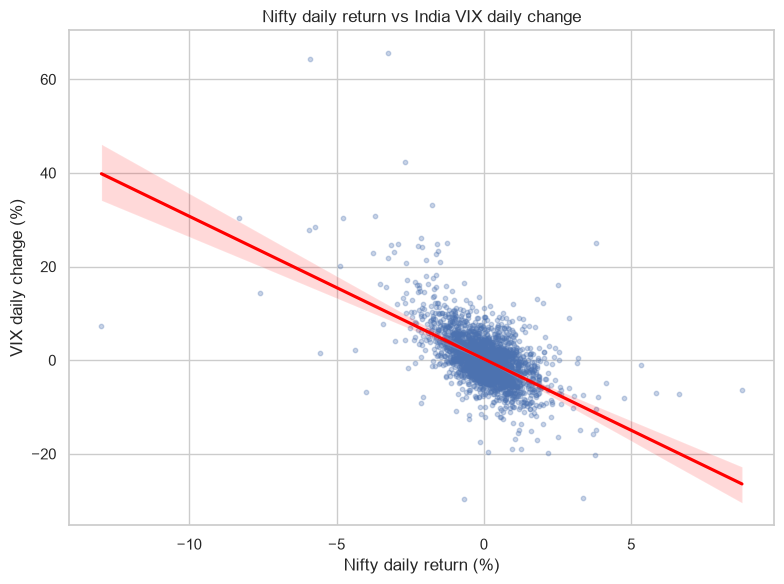

In [35]:
plt.figure(figsize=(8, 6))
sns.regplot(x=m["ret"] * 100, y=m["vix_chg"] * 100,
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
plt.title("Nifty daily return vs India VIX daily change")
plt.xlabel("Nifty daily return (%)")
plt.ylabel("VIX daily change (%)")
save_fig("08_return_vs_vix_change")

### VIX vs the volatility that actually followed

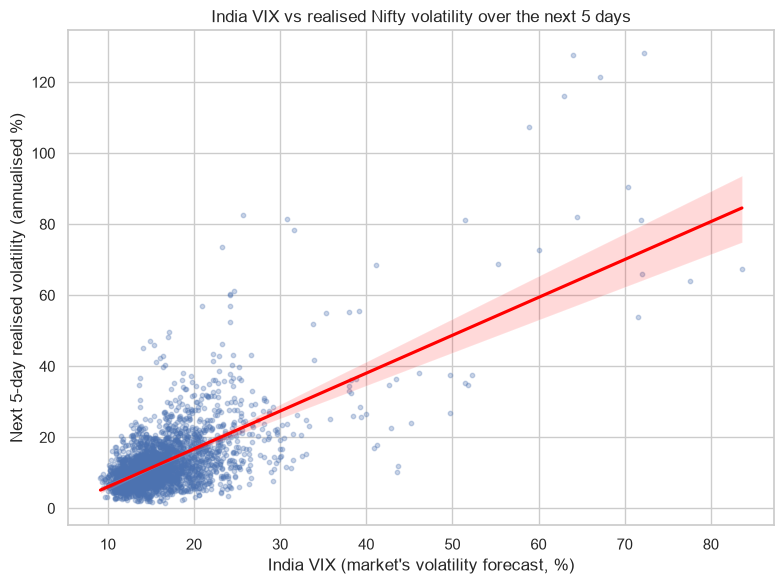

In [36]:
plt.figure(figsize=(8, 6))
sns.regplot(x=m["vix"], y=m["future_rv_5d"],
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
plt.title("India VIX vs realised Nifty volatility over the next 5 days")
plt.xlabel("India VIX (market's volatility forecast, %)")
plt.ylabel("Next 5-day realised volatility (annualised %)")
save_fig("09_vix_vs_future_volatility")

### Correlation Heatmap

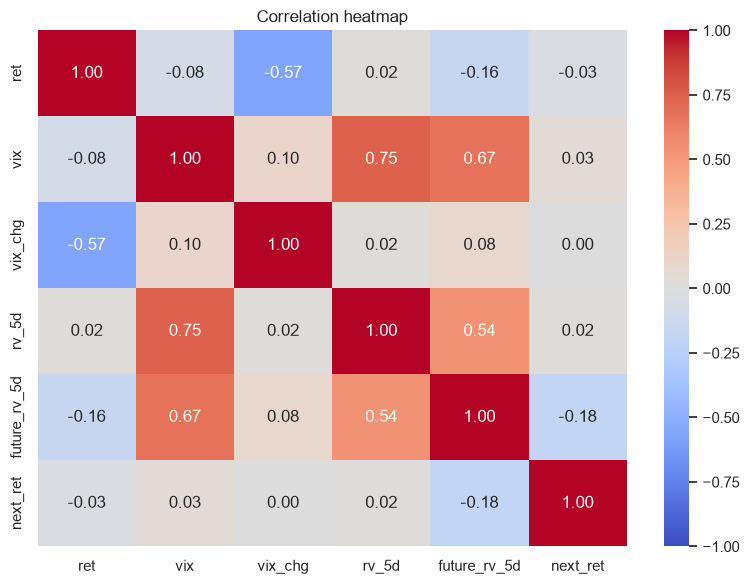

In [37]:
cols = ["ret", "vix", "vix_chg", "rv_5d", "future_rv_5d", "next_ret"]
corr = m[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap")
save_fig("10_correlation_heatmap")

## Stationarity (ADF) tests

In [42]:
from statsmodels.tsa.stattools import adfuller

def adf_report(series, label):
    stat, pvalue, *_ = adfuller(series.dropna(), autolag="AIC", result_object=False)
    verdict = "stationary" if pvalue < 0.05 else "NON-stationary"
    print(f"{label:<28} ADF stat = {stat:>7.2f} | p-value = {pvalue:.4f} -> {verdict}")

adf_report(m["close"], "Nifty close (price)")
adf_report(m["ret"], "Nifty daily return")
adf_report(m["vix"], "India VIX level")
adf_report(m["vix"].diff(), "India VIX daily difference")

Nifty close (price)          ADF stat =   -0.17 | p-value = 0.9419 -> NON-stationary
Nifty daily return           ADF stat =  -14.98 | p-value = 0.0000 -> stationary
India VIX level              ADF stat =   -4.67 | p-value = 0.0001 -> stationary
India VIX daily difference   ADF stat =  -14.19 | p-value = 0.0000 -> stationary


## ACF plots

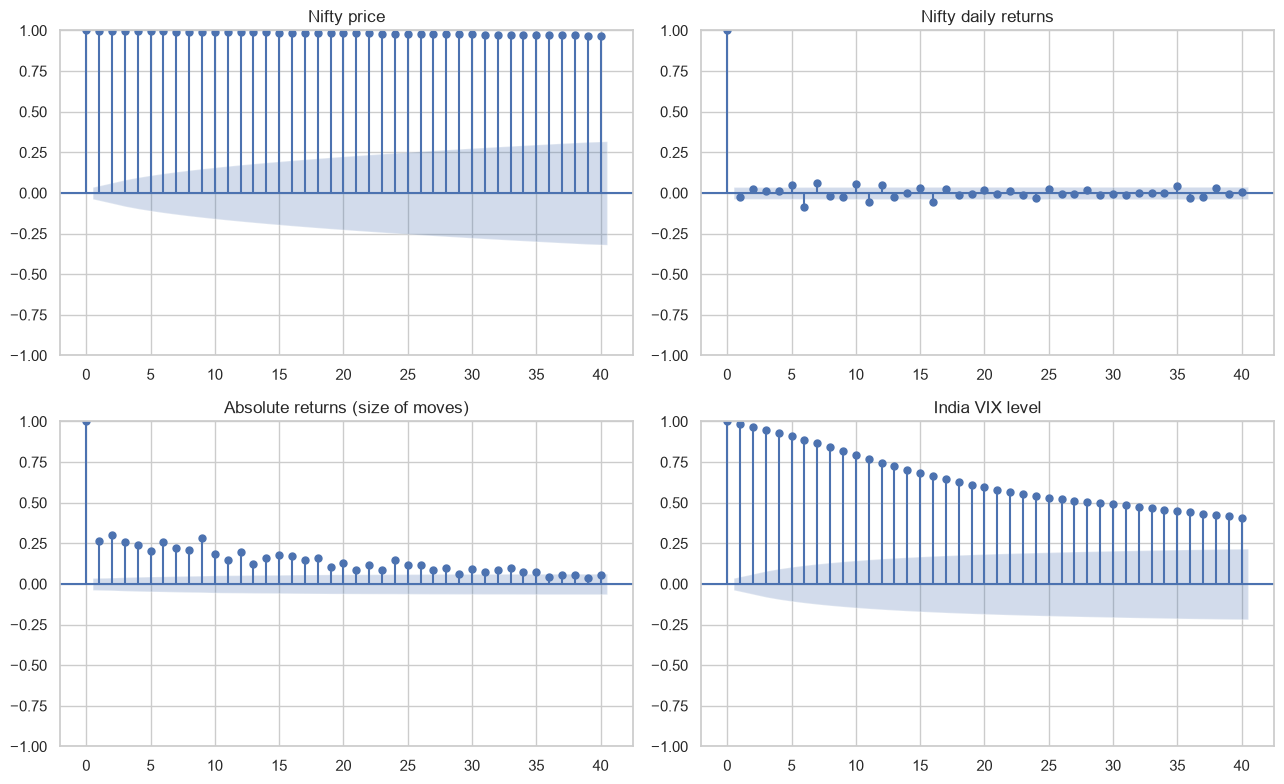

In [40]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_acf(m["close"], lags=40, ax=axes[0, 0], title="Nifty price")
plot_acf(m["ret"], lags=40, ax=axes[0, 1], title="Nifty daily returns")
plot_acf(m["ret"].abs(), lags=40, ax=axes[1, 0], title="Absolute returns (size of moves)")
plot_acf(m["vix"], lags=40, ax=axes[1, 1], title="India VIX level")
save_fig("11_autocorrelation")

## the same numbers in a table

In [41]:
lags = [1, 2, 3, 5, 10, 20]
table = pd.DataFrame({
    "return": [m["ret"].autocorr(l) for l in lags],
    "absolute return": [m["ret"].abs().autocorr(l) for l in lags],
    "VIX level": [m["vix"].autocorr(l) for l in lags],
}, index=pd.Index(lags, name="lag (days)"))

display(table.round(3))

,return,absolute return,VIX level
lag (days),,,
1,-0.03,0.26,0.98
2,0.02,0.30,0.97
3,0.01,0.26,0.95
5,0.05,0.20,0.91
10,0.06,0.18,0.80
20,0.02,0.13,0.59
